# 1. Perkenalan Dataset

Eksperimen ini menggunakan dataset Iris yang tersedia melalui scikit-learn. Dataset berisi 150 pengamatan bunga Iris, empat fitur pengukuran dalam cm, dan tiga kelas spesies. Tujuan eksperimen adalah menyiapkan data untuk klasifikasi spesies bunga.

# 2. Import Library

Pustaka berikut digunakan untuk memuat dan mengolah data, membuat visualisasi, membagi data, serta melakukan imputasi dan standardisasi.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 3. Memuat Dataset

Dataset dimuat dari fungsi `load_iris` milik scikit-learn. `as_frame=True` menghasilkan data berbentuk DataFrame sehingga mudah diperiksa menggunakan pandas.

In [2]:
iris = load_iris(as_frame=True)
data = iris.data.copy()
data["target"] = iris.target
data["species"] = data["target"].map(dict(enumerate(iris.target_names)))

print("Ukuran dataset:", data.shape)
print("\nLima baris pertama:")
display(data.head())
print("\nNama fitur:", list(iris.feature_names))
print("Kelas target:", list(iris.target_names))

Ukuran dataset: (150, 6)

Lima baris pertama:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



Nama fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Kelas target: ['setosa', 'versicolor', 'virginica']


# 4. Exploratory Data Analysis (EDA)

EDA memeriksa struktur, statistik fitur, nilai kosong, baris duplikat, distribusi kelas, dan distribusi setiap fitur.

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int32  
 5   species            150 non-null    object 
dtypes: float64(4), int32(1), object(1)
memory usage: 6.6+ KB

Statistik deskriptif fitur:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5



Jumlah nilai kosong per kolom:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Jumlah baris duplikat: 1

Jumlah data per spesies:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


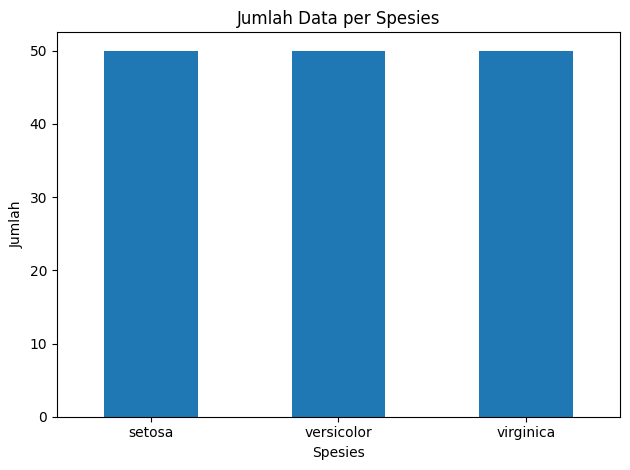

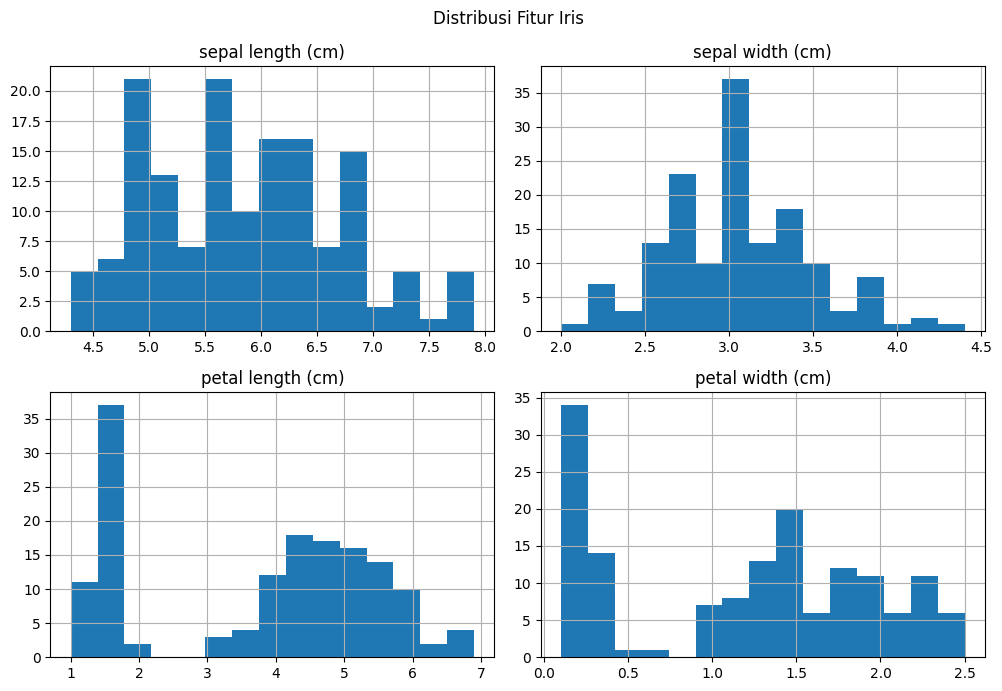

In [3]:
print("Informasi dataset:")
data.info()
print("\nStatistik deskriptif fitur:")
display(data[iris.feature_names].describe().T)
print("\nJumlah nilai kosong per kolom:")
print(data.isna().sum())
print("\nJumlah baris duplikat:", data.duplicated().sum())
print("\nJumlah data per spesies:")
print(data["species"].value_counts())

data["species"].value_counts().reindex(iris.target_names).plot.bar(
    title="Jumlah Data per Spesies", xlabel="Spesies", ylabel="Jumlah", rot=0
)
plt.tight_layout()
plt.show()

data[iris.feature_names].hist(figsize=(10, 7), bins=15)
plt.suptitle("Distribusi Fitur Iris")
plt.tight_layout()
plt.show()

# 5. Data Preprocessing

Baris duplikat tetap diperiksa dan dilaporkan; pengamatan tidak dihapus secara otomatis. Target sudah berupa angka (0, 1, 2), sehingga tidak memerlukan encoding. Data dibagi secara stratified menjadi data latih dan data uji. Imputer dan scaler hanya di-fit pada data latih untuk mencegah kebocoran informasi dari data uji.

In [4]:
X = data[iris.feature_names]
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_preprocessed = scaler.fit_transform(X_train_imputed)
X_test_preprocessed = scaler.transform(X_test_imputed)

print("Ukuran data latih:", X_train_preprocessed.shape)
print("Ukuran data uji:", X_test_preprocessed.shape)
print("Jumlah nilai kosong setelah imputasi:", pd.isna(X_train_preprocessed).sum())
print("Label target (0, 1, 2):", dict(enumerate(iris.target_names)))

Ukuran data latih: (120, 4)
Ukuran data uji: (30, 4)
Jumlah nilai kosong setelah imputasi: 0
Label target (0, 1, 2): {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
